# 03 · Equal-budget hyper-parameter search

Each architecture gets the same number of randomly sampled configurations, the same training
data, the same epoch cap and the same seed. The selection criterion is the area under the
precision-recall curve on the **SisFall validation subjects**: with ~5% positives, AUPRC
separates good and mediocre detectors far better than AUROC, which saturates.

Daphnet AUROC is also logged for every configuration. It is **not** used for selection. It
only lets us report, at the end, how much an oracle that peeks at target labels could gain
(the "test-domain validation" upper bound of Gulrajani & Lopez-Paz, 2021).

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C
from src.engine import predict_proba, train_model
from src.experiment import daphnet_views, load_all, load_scaler, sisfall_splits
from src.models import build_model, count_params
from src.plotting import save, set_style

set_style()
X_sis, meta_sis, X_dap, meta_dap = load_all()
src_scaler, tgt_scaler = load_scaler("source"), load_scaler("target")
S = sisfall_splits(X_sis, meta_sis, src_scaler)
X_dap_dom = tgt_scaler.transform(X_dap)
y_dap = meta_dap.label.values
print({k: v["X"].shape for k, v in S.items()}, X_dap_dom.shape)

{'train': (49582, 128, 4), 'val': (8967, 128, 4), 'test': (14554, 128, 4)} (17410, 128, 4)


## Search spaces

The spaces are sized so that every architecture can reach a similar parameter range
(roughly 10k-200k).

In [2]:
SPACES = {
    "CNN-1D": {"width": [16, 32, 48], "kernel": [5, 7, 9], "dropout": [0.1, 0.3, 0.5],
               "lr": [5e-4, 1e-3, 3e-3]},
    "LSTM": {"hidden": [32, 64, 96], "layers": [1, 2], "dropout": [0.1, 0.3],
             "bidirectional": [False, True], "lr": [5e-4, 1e-3, 3e-3]},
    "GRU": {"hidden": [32, 64, 96], "layers": [1, 2], "dropout": [0.1, 0.3],
            "bidirectional": [False, True], "lr": [5e-4, 1e-3, 3e-3]},
    "Transformer": {"d_model": [32, 64, 96], "layers": [2, 3, 4], "patch": [8, 16],
                    "heads": [4], "dropout": [0.1, 0.2], "lr": [5e-4, 1e-3, 3e-3]},
}
N_CONFIGS = 6
SEARCH_EPOCHS = 5
SEARCH_NEG_FRAC = 0.5   # half of the training negatives, same subset for every architecture

rng = np.random.default_rng(2026)
configs = {}
for arch, space in SPACES.items():
    seen, cfgs = set(), []
    while len(cfgs) < N_CONFIGS:
        c = {k: v[rng.integers(len(v))] for k, v in space.items()}
        c = {k: (v.item() if hasattr(v, "item") else v) for k, v in c.items()}
        key = json.dumps(c, sort_keys=True)
        if key not in seen:
            seen.add(key)
            cfgs.append(c)
    configs[arch] = cfgs

sub_rng = np.random.default_rng(0)
y_tr = S["train"]["y"]
keep = (y_tr == 1) | (sub_rng.random(len(y_tr)) < SEARCH_NEG_FRAC)
Xs_g, ys = S["train"]["X_g"][keep], y_tr[keep]
print("search training set:", Xs_g.shape, "positives:", int(ys.sum()))

search training set: (27267, 128, 4) positives: 4877


In [3]:
log_path = C.LOGS / "hparam_search.log"
rows = []
done = set()
csv_path = C.METRICS / "hparam_search.csv"
if csv_path.exists():
    prev = pd.read_csv(csv_path)
    rows = prev.to_dict("records")
    done = {(r["arch"], r["config"]) for r in rows}

for arch in C.ARCHS:
    for i, hp in enumerate(configs[arch]):
        key = json.dumps(hp, sort_keys=True)
        if (arch, key) in done:
            continue
        model_hp = {k: v for k, v in hp.items() if k != "lr"}
        t0 = time.time()
        model, hist, info = train_model(
            arch, model_hp, Xs_g, ys, S["val"]["X"], S["val"]["y"], src_scaler,
            cfg={"epochs": SEARCH_EPOCHS, "patience": 2, "lr": hp["lr"]}, seed=0, verbose=False,
            log_fn=lambda m: open(log_path, "a").write(m + "\n"))
        p_val = predict_proba(model, S["val"]["X"])
        p_dap = predict_proba(model, X_dap_dom)
        rows.append({"arch": arch, "config_id": i, "config": key, "params": count_params(model),
                     "best_epoch": info["best_epoch"], "val_auprc": average_precision_score(S["val"]["y"], p_val),
                     "val_loss": hist[info["best_epoch"] - 1]["val_loss"],
                     "val_auroc": roc_auc_score(S["val"]["y"], p_val),
                     "daphnet_auroc_oracle_only": roc_auc_score(y_dap, p_dap),
                     "minutes": (time.time() - t0) / 60})
        print(f"{arch:12s} cfg{i} {key}  val AUPRC {rows[-1]['val_auprc']:.4f}  "
              f"({rows[-1]['minutes']:.1f} min, {rows[-1]['params']} params)", flush=True)
        pd.DataFrame(rows).to_csv(csv_path, index=False)

res = pd.DataFrame(rows)
res.sort_values(["arch", "val_auprc"], ascending=[True, False])

,arch,config_id,config,params,best_epoch,val_auprc,val_loss,val_auroc,daphnet_auroc_oracle_only,minutes
0,CNN-1D,0,"{""dropout"": 0.1, ""kernel"": 5, ""lr"": 0.001, ""wi...",70945,4,1.000000,0.006666,1.000000,0.432772,0.231117
2,CNN-1D,2,"{""dropout"": 0.5, ""kernel"": 7, ""lr"": 0.003, ""wi...",36289,4,1.000000,0.003169,1.000000,0.541321,0.068858
3,CNN-1D,3,"{""dropout"": 0.5, ""kernel"": 9, ""lr"": 0.0005, ""w...",127009,4,1.000000,0.015035,1.000000,0.558006,0.122834
4,CNN-1D,4,"{""dropout"": 0.1, ""kernel"": 7, ""lr"": 0.0005, ""w...",80545,4,1.000000,0.015213,1.000000,0.516066,0.078526
5,CNN-1D,5,"{""dropout"": 0.5, ""kernel"": 9, ""lr"": 0.003, ""wi...",14689,4,1.000000,0.005357,1.000000,0.687532,0.065545
1,CNN-1D,1,"{""dropout"": 0.1, ""kernel"": 7, ""lr"": 0.001, ""wi...",36289,4,0.999981,0.009900,1.000000,0.547295,0.114365
12,GRU,0,"{""bidirectional"": true, ""dropout"": 0.1, ""hidde...",26241,5,1.000000,0.005691,1.000000,0.653561,0.127275
13,GRU,1,"{""bidirectional"": true, ""dropout"": 0.3, ""hidde...",226177,3,1.000000,0.007617,1.000000,0.518155,0.329858
17,GRU,5,"{""bidirectional"": true, ""dropout"": 0.1, ""hidde...",7425,5,0.999962,0.030494,0.999999,0.563293,0.109095
14,GRU,2,"{""bidirectional"": true, ""dropout"": 0.3, ""hidde...",27137,4,0.999924,0.010975,0.999998,0.455203,0.118219


## Selected configurations

Impact-centred fall windows turn out to be easy to separate: several configurations reach a
validation AUPRC within 0.001 of each other. Differences that small are noise, so AUPRC is
rounded to three decimals and ties are broken by the (unweighted) validation cross-entropy,
which still discriminates between well and poorly calibrated models.

In [4]:
res["val_auprc_r"] = res.val_auprc.round(3)
best = {}
for arch in C.ARCHS:
    r = res[res.arch == arch].sort_values(["val_auprc_r", "val_loss"], ascending=[False, True]).iloc[0]
    best[arch] = json.loads(r.config)
    print(f"{arch:12s} {best[arch]}  val AUPRC {r.val_auprc:.4f}  params {r.params}")
with open(C.METRICS / "best_hparams.json", "w") as fh:
    json.dump(best, fh, indent=2)

oracle = res.loc[res.groupby("arch").daphnet_auroc_oracle_only.idxmax(),
                 ["arch", "config_id", "val_auprc", "daphnet_auroc_oracle_only"]]
oracle.to_csv(C.METRICS / "hparam_oracle_selection.csv", index=False)
oracle

CNN-1D       {'dropout': 0.5, 'kernel': 7, 'lr': 0.003, 'width': 32}  val AUPRC 1.0000  params 36289
LSTM         {'bidirectional': True, 'dropout': 0.3, 'hidden': 64, 'layers': 2, 'lr': 0.001}  val AUPRC 1.0000  params 135425
GRU          {'bidirectional': True, 'dropout': 0.1, 'hidden': 32, 'layers': 2, 'lr': 0.003}  val AUPRC 1.0000  params 26241
Transformer  {'d_model': 64, 'dropout': 0.2, 'heads': 4, 'layers': 2, 'lr': 0.003, 'patch': 8}  val AUPRC 1.0000  params 70401


,arch,config_id,val_auprc,daphnet_auroc_oracle_only
5,CNN-1D,5,1.000000,0.687532
12,GRU,0,1.000000,0.653561
11,LSTM,5,0.999885,0.524379
19,Transformer,1,1.000000,0.656521


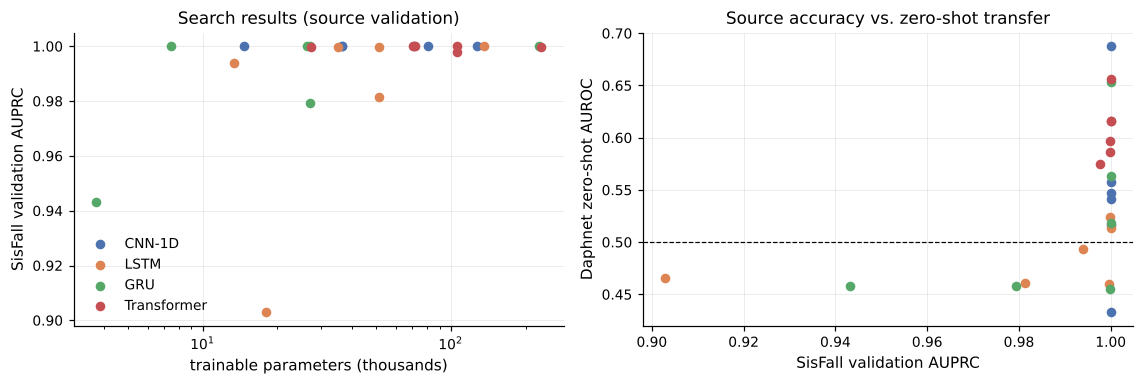

Spearman correlation, val AUPRC vs Daphnet AUROC: 0.479


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for arch in C.ARCHS:
    r = res[res.arch == arch]
    axes[0].scatter(r.params / 1e3, r.val_auprc, color=C.PALETTE[arch], label=arch, s=28)
    axes[1].scatter(r.val_auprc, r.daphnet_auroc_oracle_only, color=C.PALETTE[arch], label=arch, s=28)
axes[0].set_xscale("log")
axes[0].set_xlabel("trainable parameters (thousands)")
axes[0].set_ylabel("SisFall validation AUPRC")
axes[0].set_title("Search results (source validation)")
axes[1].axhline(0.5, ls="--", c="k", lw=0.8)
axes[1].set_xlabel("SisFall validation AUPRC")
axes[1].set_ylabel("Daphnet zero-shot AUROC")
axes[1].set_title("Source accuracy vs. zero-shot transfer")
axes[0].legend(frameon=False)
fig.tight_layout()
save(fig, "fig11_hparam_search")
print("Spearman correlation, val AUPRC vs Daphnet AUROC:",
      round(res[["val_auprc", "daphnet_auroc_oracle_only"]].corr("spearman").iloc[0, 1], 3))